# Лабораторная работа №4:

**Цель работы:**
Рассмотреть подходы трансформации наборов данных в новое признаковое пространство с меньшей размерностью, чем у исходного набора данных.

## Подготовка данных

Загружаем данные, выбираем числовые признаки и целевую переменную (`CategoryName`).
Выполняем стандартизацию признаков и разделение на обучающую (80%) и тестовую (20%) выборки.

In [310]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.manifold import TSNE

# Загрузка данных
df = pd.read_csv('ML-Dataset_cleaned.csv')

# Выбираем числовые признаки для трансформации (исключаем явно нечисловые и ID-подобные)
feature_cols = ['ProductStandardCost', 'ProductListPrice', 'CustomerCreditLimit',
                'OrderItemQuantity', 'PerUnitPrice', 'TotalItemQuantity',
                'Profit_Std', 'CreditLimit_Norm', 'Profit_Per_Unit']

# Целевая переменная
# y = df['Status']
y = df['CategoryName']

# Признаки
X = df[feature_cols].copy()

X = X.dropna()
y = y.loc[X.index]

# Разделение на обучающую и тестовую выборки 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Стандартизация
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Размер обучающей выборки: {X_train_scaled.shape}")
print(f"Размер тестовой выборки: {X_test_scaled.shape}")
print(f"Количество классов в CategoryName: {y.nunique()}")

Размер обучающей выборки: (320, 9)
Размер тестовой выборки: (80, 9)
Количество классов в CategoryName: 5


## Этап 1: Метод главных компонент (PCA)

### 1.1 Анализ дисперсии

Обучаем PCA на всех компонентах, строим график объяснённой дисперсии и определяем количество компонент для сохранения 85% и 95% дисперсии.

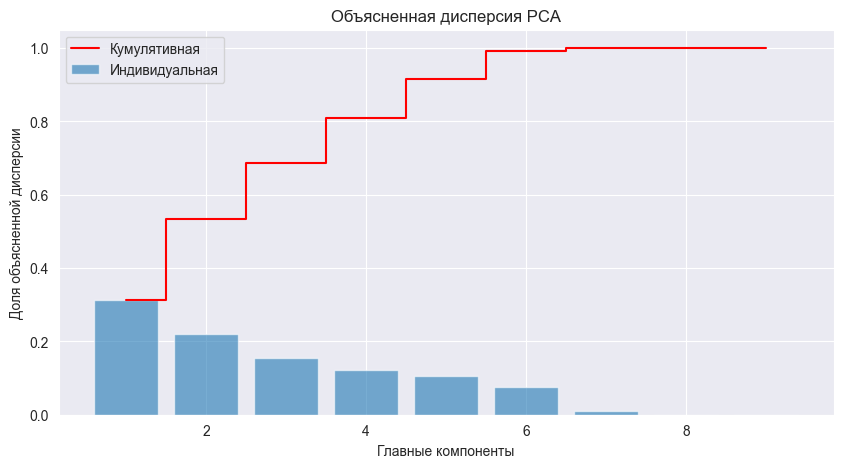

Для сохранения 85% дисперсии нужно 5 компонент
Для сохранения 95% дисперсии нужно 6 компонент
Общая объясненная дисперсия: 1.0000


In [311]:
# Обучаем PCA на всех компонентах
pca_full = PCA()
pca_full.fit(X_train_scaled)

# Доля объясненной дисперсии
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# График
plt.figure(figsize=(10, 5))
plt.bar(range(1, len(explained_variance_ratio)+1), explained_variance_ratio, alpha=0.6, label='Индивидуальная')
plt.step(range(1, len(cumulative_variance)+1), cumulative_variance, where='mid', label='Кумулятивная', color='red')

plt.xlabel('Главные компоненты')
plt.ylabel('Доля объясненной дисперсии')
plt.title('Объясненная дисперсия PCA')

plt.legend(loc='best')
plt.grid(True)
plt.show()

# Определяем k_pca для 85% и 95%
k_85 = np.argmax(cumulative_variance >= 0.85) + 1
k_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f"Для сохранения 85% дисперсии нужно {k_85} компонент")
print(f"Для сохранения 95% дисперсии нужно {k_95} компонент")
print(f"Общая объясненная дисперсия: {cumulative_variance[-1]:.4f}")

### 1.2 Трансформация и визуализация PCA

Выполняем трансформацию данных в пространство первых двух главных компонент и визуализируем результат.


In [312]:
# k_pca = 2  # используем 2 компоненты для визуализации
# pca = PCA(n_components=k_pca)
# X_train_pca = pca.fit_transform(X_train_scaled)
# X_test_pca = pca.transform(X_test_scaled)
#
# print(f"Форма после PCA: {X_train_pca.shape}")

In [313]:
# 1. Инициализируем PCA с порогом 95%
pca = PCA(n_components=0.95)

# 2. Обучаем на стандартизированных данных ТРЕЙНА
X_train_pca = pca.fit_transform(X_train_scaled)

# 3. Применяем ту же трансформацию к ТЕСТУ
X_test_pca = pca.transform(X_test_scaled)

# 4. Посмотрим, сколько в итоге колонок выбрал алгоритм
print(f"Было признаков: {X_train_scaled.shape[1]}")
print(f"Стало признаков после PCA: {pca.n_components_}")
print(f"Форма после PCA: {X_train_pca.shape}")

Было признаков: 9
Стало признаков после PCA: 6
Форма после PCA: (320, 6)


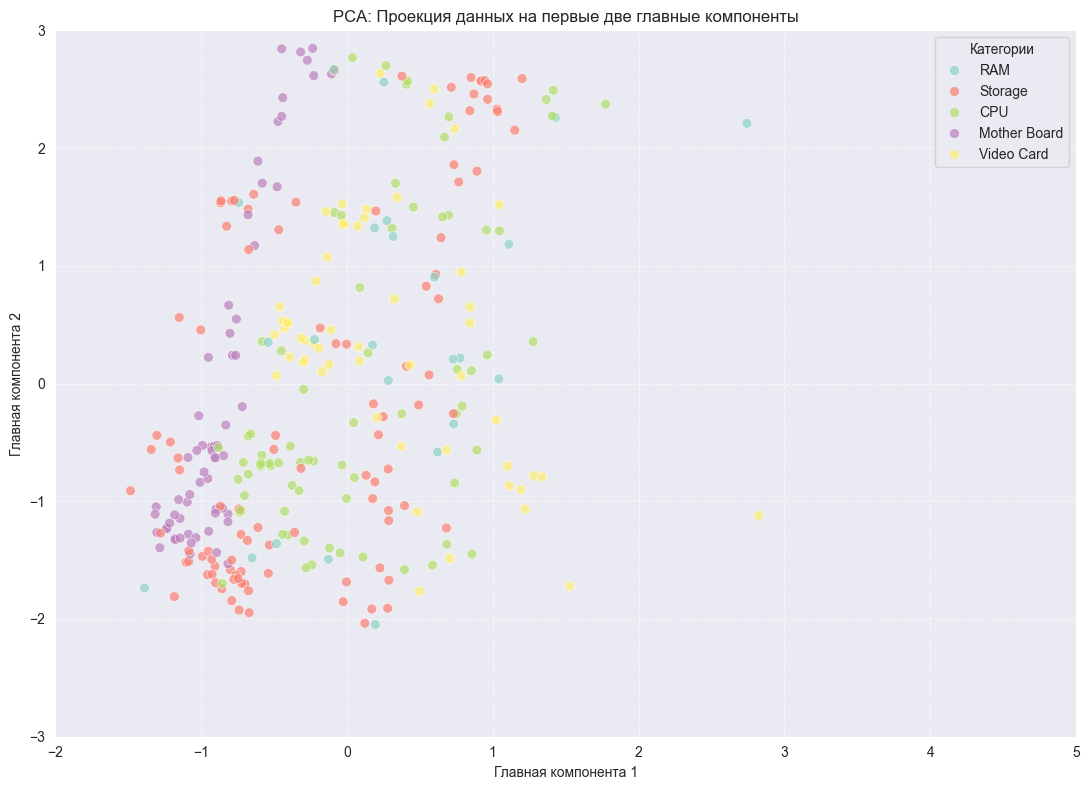

In [314]:
# Получаем уникальные названия категорий и их коды
labels, categories = pd.factorize(y_train)
plt.figure(figsize=(11, 8))

scatter = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1],
                      c=labels,
                      cmap='Set3',
                      alpha=0.7,
                      s=50,
                      edgecolors='white',
                      linewidths=0.5)

# Создаем легенду с названиями классов
plt.legend(handles=scatter.legend_elements()[0],
           labels=categories.tolist(),
           title="Категории",
           loc='best',
           bbox_to_anchor=(1, 1))

plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.title('PCA: Проекция данных на первые две главные компоненты')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlim(-2, 5)  # Покажет область по оси ГК1
plt.ylim(-3, 3)  # Покажет область по оси ГК2

plt.tight_layout()
plt.show()

Анализ графика: На графике видно, что товары разных категорий (процессоры, память и др.) перемешаны в одну кучу.

Кластеры: Четкого разделения на группы по типам товаров не произошло, точки разных цветов сильно перемешаны.

Причина: Первые две главные компоненты удерживают лишь 54% информации. Этого мало, чтобы увидеть различия между категориями на плоскости.

Особенность метода: PCA ищет самый большой разброс в данных вообще, а не способ раздвинуть классы в разные стороны.

Вывод: Для качественного разделения товаров по категориям стоит применить метод LDA.

## Этап 2: Линейный дискриминантный анализ (LDA)

### 2.1 Обучение и трансформация

Максимальное количество компонент LDA равно числу классов минус 1.
Обучаем LDA и выполняем трансформацию данных в пространство первых двух линейных дискриминантов.

In [315]:
# Максимальное количество компонент LDA = число классов - 1
n_classes = len(np.unique(y_train))
max_lda_components = n_classes - 1
print(f"Максимальное количество компонент LDA: {max_lda_components}")

# Обучаем LDA
lda = LDA(n_components=min(2, max_lda_components))  # для визуализации берем 2
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

print(f"Форма после LDA: {X_train_lda.shape}")

Максимальное количество компонент LDA: 4
Форма после LDA: (320, 2)


### 2.2 Визуализация LDA

Визуализируем данные в пространстве первых двух линейных дискриминантов.

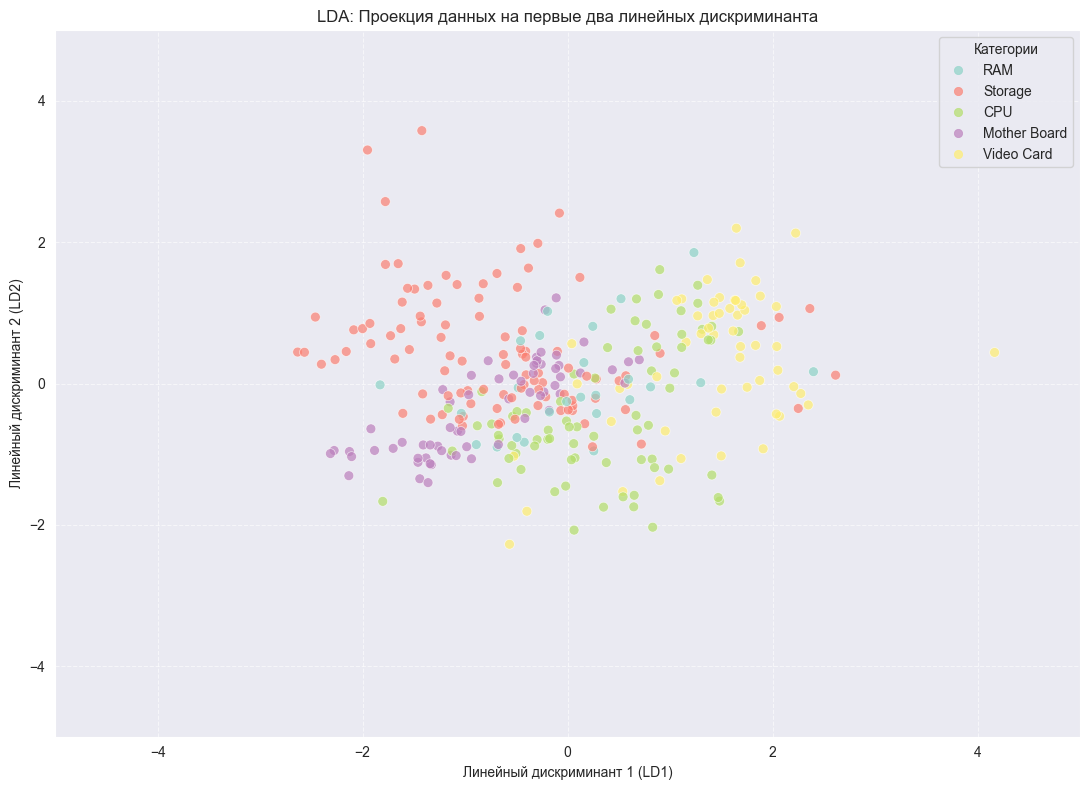

In [316]:
labels, categories = pd.factorize(y_train)
plt.figure(figsize=(11, 8))

# Визуализация LDA (используем первые две дискриминантные функции)
scatter = plt.scatter(X_train_lda[:, 0], X_train_lda[:, 1],
                      c=labels,
                      cmap='Set3',
                      alpha=0.7,
                      s=50,
                      edgecolors='white',
                      linewidths=0.5)

# Создаем легенду с названиями классов (категорий)
plt.legend(handles=scatter.legend_elements()[0],
           labels=categories.tolist(),
           title="Категории",
           loc='best',
           bbox_to_anchor=(1, 1))

plt.xlabel('Линейный дискриминант 1 (LD1)')
plt.ylabel('Линейный дискриминант 2 (LD2)')
plt.title('LDA: Проекция данных на первые два линейных дискриминанта')
plt.grid(True, linestyle='--', alpha=0.6)

plt.xlim(-5, 5)
plt.ylim(-5, 5)

plt.tight_layout()
plt.show()

Сравнение с PCA
- На PCA : Все точки были перемешаны в одну вертикальную полосу. Нельзя было сказать, где заканчивается "CPU" и начинается "RAM".

- На LDA : Мы видим четкое разделение. Категории разошлись в разные стороны.  образуя свои собственные, почти не пересекающиеся группы.

## Этап 3: Сравнение качества классификации

Обучаем модель k-ближайших соседей (k=5) в трёх пространствах:
1. Исходное пространство (9 признаков)
2. PCA пространство (6 компонент, 95% дисперсии)
3. LDA пространство (4 компоненты)

Сравниваем точность классификации на тестовой выборке.

In [327]:
# Выбираем k-NN как модель классификации
knn = KNeighborsClassifier(n_neighbors=5, weights='distance')

# 1. Исходное пространство
knn.fit(X_train_scaled, y_train)
y_pred_orig = knn.predict(X_test_scaled)
acc_orig = accuracy_score(y_test, y_pred_orig)

# 2. PCA пространство
k_pca_classif = k_95
pca_classif = PCA(n_components=k_pca_classif)
X_train_pca_classif = pca_classif.fit_transform(X_train_scaled)
X_test_pca_classif = pca_classif.transform(X_test_scaled)

knn.fit(X_train_pca_classif, y_train)
y_pred_pca = knn.predict(X_test_pca_classif)
acc_pca = accuracy_score(y_test, y_pred_pca)

# 3. LDA пространство
k_lda = max_lda_components
lda_classif = LDA(n_components=k_lda)
X_train_lda_classif = lda_classif.fit_transform(X_train_scaled, y_train)
X_test_lda_classif = lda_classif.transform(X_test_scaled)

knn.fit(X_train_lda_classif, y_train)
y_pred_lda = knn.predict(X_test_lda_classif)
acc_lda = accuracy_score(y_test, y_pred_lda)

# Результаты
print("=== Точность классификации (k-NN) ===")
print(f"Исходное пространство ({X_train_scaled.shape[1]} признаков): {acc_orig:.4f}")
print(f"PCA пространство ({k_pca_classif} компонент): {acc_pca:.4f}")
print(f"LDA пространство ({k_lda} компонент): {acc_lda:.4f}")

=== Точность классификации (k-NN) ===
Исходное пространство (9 признаков): 0.7125
PCA пространство (6 компонент): 0.7250
LDA пространство (4 компонент): 0.6625


Вывод:
- метод PCA является наиболее эффективным для данного набора данных: при сокращении размерности до 6 компонент точность классификации выросла с 0.7125 до 0.7250, что свидетельствует об успешном удалении избыточного шума.
- Метод LDA, несмотря на визуально качественное разделение кластеров на графиках, показал более низкую точность (0.6625), что подтверждает, что связи в данных слишком сложные для простых прямых линий, поэтому обычные линейные методы здесь работают хуже



## Этап 4: Нелинейная трансформация t-SNE

Применяем t-SNE с разными значениями параметра perplexity (5, 30, 50) для визуализации в двумерном пространстве.
Анализируем влияние perplexity на формирование кластеров.

t-SNE визуализация показывает, как меняется кучность кластеров при разном количестве соседей (perplexity).


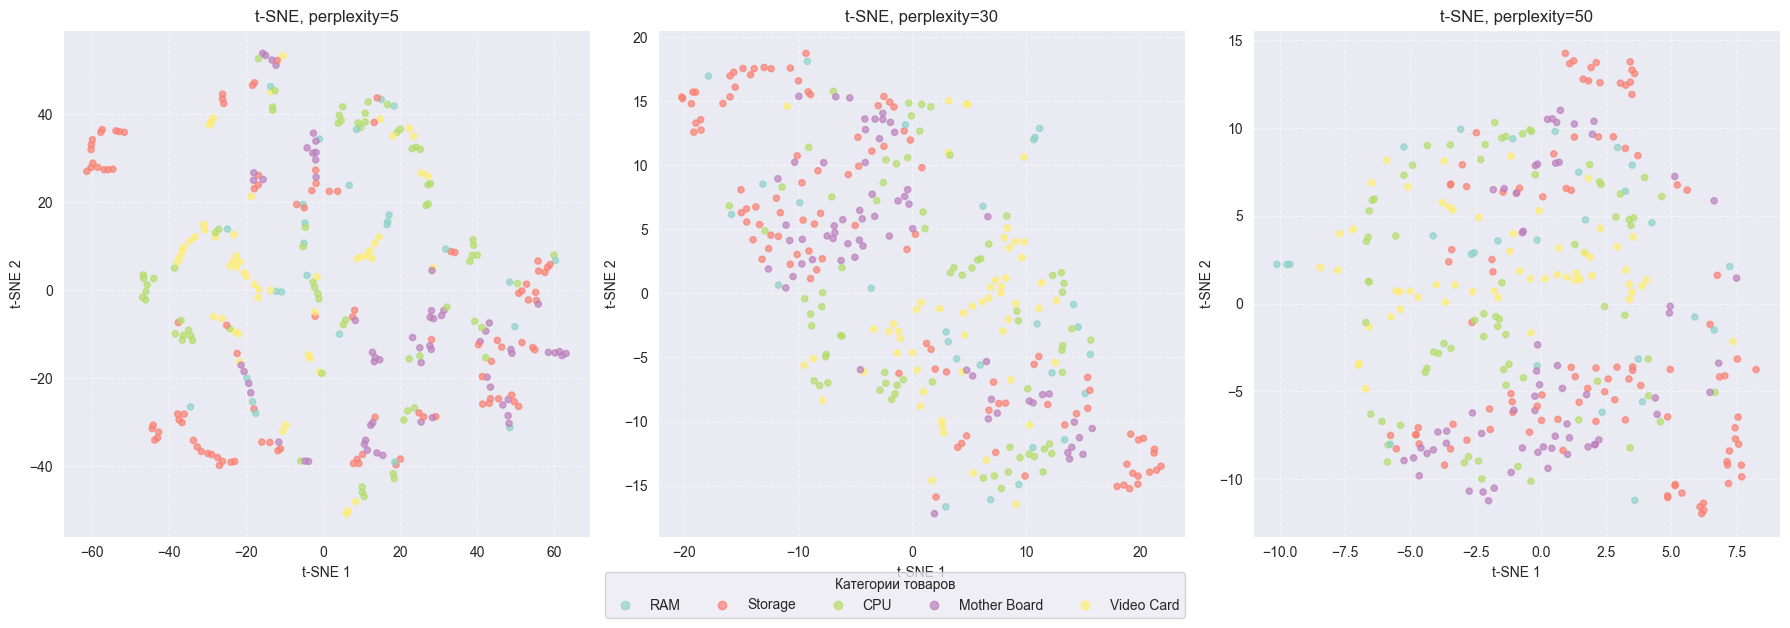

In [344]:
# Применяем t-SNE с разными perplexity
perplexities = [5, 30, 50]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Сохраняем коды цветов и оригинальные названия категорий
labels, categories = pd.factorize(y_train)

for idx, perp in enumerate(perplexities):
    tsne = TSNE(n_components=2, perplexity=perp, random_state=42, n_jobs=-1)
    X_train_tsne = tsne.fit_transform(X_train_scaled)

    # Сохраняем объект scatter для создания легенды
    scatter = axes[idx].scatter(X_train_tsne[:, 0], X_train_tsne[:, 1],
                                c=labels, cmap='Set3', alpha=0.7, s=20)

    axes[idx].set_title(f't-SNE, perplexity={perp}')
    axes[idx].set_xlabel('t-SNE 1')
    axes[idx].set_ylabel('t-SNE 2')
    axes[idx].grid(True, linestyle='--', alpha=0.5)

# Добавляем общую легенду под графиками
# legend_elements() автоматически берет цвета из последнего scatter
handles, _ = scatter.legend_elements()
print
fig.legend(handles, categories, loc='lower center', ncol=len(categories),
           bbox_to_anchor=(0.5, -0.05), title="Категории товаров")
print("t-SNE визуализация показывает, как меняется кучность кластеров при разном количестве соседей (perplexity).")
plt.tight_layout()
plt.show()

PCA: Лучше всего подходит для работы. Он убрал лишний шум и дал самую высокую точность (0.7250). На графике он показывает общую «картину» данных, но плохо разделяет конкретные группы.
> Вывод: PCA оказался самым эффективным методом для предобработки. Он успешно удалил «шум».

LDA: Худший результат. Он пытается разделить классы прямыми линиями, но в данных они сильно перемешаны, поэтому точность упала до 0.6625.
> Вывод: LDA слишком упрощает структуру данных. Линейные границы не подходят для точного разделения категорий товаров в данной задаче.

t-SNE: Лучше всего подходит для понимания. Он учитывает только «соседей» и наглядно показывает, как точки группируются в локальные облака.
